In [8]:
# model COST
import numpy as np
import pandas as pd
import gurobipy as gp
from gurobipy import GRB
import random
import matplotlib.pyplot as plt
import time

# 🔥 🔥 🔥 新版本：可控密度的生成计划函数
def select_alpha_range(target_daily_tasks):
    """根据目标日均任务数，选择合适的退化率范围"""
    if target_daily_tasks <= 5:  # 稀疏
        # return 0.004, 0.006
        return 0.001, 0.002
    elif 6 <= target_daily_tasks <= 12:  # 中等
        return 0.010, 0.013
    else:  # 13+ 密集
        return 0.020, 0.025


def generate_tasks_fixed_density(N, T, target_daily_tasks, seed=42):
    """根据目标任务密度生成维护计划"""
    random.seed(seed)

    caissons = list(range(N))
    initial_p_values = {c: round(random.uniform(3.2, 3.5), 2) for c in caissons}

    a, b = select_alpha_range(target_daily_tasks)
    alpha_values = {c: round(random.uniform(a, b), 6) for c in caissons}

    columns = ['INDEX', 'CSEM', 'INITIALP', 'OPERATION', 'DATE']
    data = []

    index = 0
    for caisson in caissons:
        initial_p = initial_p_values[caisson]
        current_p = initial_p
        alpha = alpha_values[caisson]
        total_days = 0

        while total_days < T:
            time_to_3_2 = int((current_p - 3.2) / alpha)
            if total_days + time_to_3_2 >= T:
                break

            data.append([index, caisson, initial_p, 'x', total_days + time_to_3_2])
            index += 1
            total_days += time_to_3_2 + 1
            current_p = 3.5

    maintenance_plan = pd.DataFrame(data, columns=columns)
    return maintenance_plan, alpha_values


# 🔥 🔥 🔥 计算维修周期（不变）
def calculate_maintenance_period_from_data(df, d_min_ratio=0.6, d_max_ratio=1.4):
    maintenance_periods = {}
    D_min_dict = {}
    D_max_dict = {}
    
    print("\n===== 从数据中提取维修周期 =====")
    print(f"{'Caisson':<10} {'间隔数':<10} {'间隔范围':<20} {'周期':<12} {'D_min':<10} {'D_max':<10}")
    print("-" * 80)
    
    for caisson_id in sorted(df['CSEM'].unique()):
        caisson_tasks = df[(df['CSEM'] == caisson_id) & (df['OPERATION'] == 'x')].sort_values('DATE')
        
        if len(caisson_tasks) < 2:
            default_period = PARAMS['window_size']
            maintenance_periods[caisson_id] = default_period
            D_min_dict[caisson_id] = int(np.ceil(default_period * d_min_ratio))
            D_max_dict[caisson_id] = int(np.ceil(default_period * d_max_ratio))
            print(f"{caisson_id:<10} ... {default_period:<12.2f} ...")  
            continue
        
        intervals = [caisson_tasks.iloc[i]['DATE'] - caisson_tasks.iloc[i-1]['DATE'] 
                    for i in range(1, len(caisson_tasks))]
        
        maintenance_period = np.mean(intervals)
        maintenance_periods[caisson_id] = maintenance_period
        D_min_dict[caisson_id] = int(np.ceil(maintenance_period * d_min_ratio))
        D_max_dict[caisson_id] = int(np.ceil(maintenance_period * d_max_ratio))
        
        interval_min, interval_max = min(intervals), max(intervals)

    
    print("===== 提取完成 =====\n")
    return maintenance_periods, D_min_dict, D_max_dict


# 🔥 🔥 🔥 Gurobi聚类函数（不变）
def clustering_CR(df_window, window_size, window_start, full_df=None, D_min_dict=None, D_max_dict=None):
    if df_window.empty or window_size < 1:
        print(f"warning: window {window_start} has no tasks")
        return df_window

    N = df_window.shape[0]
    mdl = gp.Model('Dynamic_Window_Clustering')
    mdl.setParam('OutputFlag', 0)

    data_pos_num = window_size + 1
    theta = mdl.addVars(N, data_pos_num, vtype=GRB.BINARY, name='theta')
    y = mdl.addVars(data_pos_num, vtype=GRB.BINARY, name='y')

    # 约束（完全不变）
    for n in range(N):
        mdl.addConstr(theta.sum(n, '*') == 1)
    for t in range(data_pos_num):
        mdl.addConstr(theta.sum('*', t) <= PARAMS['Cmax'])

    # 时间窗口约束
    a, b = [0] * N, [0] * N
    for n in range(N):
        local_time = int(df_window.iloc[n]['window_time'])
        a[n] = int(max(0, local_time - PARAMS['advanced']))
        b[n] = int(min(data_pos_num, local_time + int((3.2 - 3.0)/alpha_values[int(df_window.iloc[n]["CSEM"])])//2))

    for n in range(N):
        for t in range(data_pos_num):
            mdl.addConstr(t * theta[n, t] + a[n] * (1 - theta[n, t]) >= a[n])
            mdl.addConstr(t * theta[n, t] + b[n] * (1 - theta[n, t]) <= b[n])

    # 聚类激活
    M = PARAMS['Cmax']
    for t in range(data_pos_num):
        task_count = theta.sum('*', t)
        mdl.addConstr(task_count + M * (1 - y[t]) >= 1)
        mdl.addConstr(task_count <= M * y[t])

    # 目标函数：最大化利润
    setup_cost = PARAMS['Cs'] * (theta.sum() - y.sum())
    cost_matrix = {}
    for n in range(N):
        local_time_n = int(df_window.iloc[n]['window_time'])
        for t in range(data_pos_num):
            deviation = t - local_time_n
            cost_matrix[(n, t)] = PARAMS['Cbeta'] * max(0, deviation) + PARAMS['Calpha'] * max(0, -deviation)
    
    CP_total = gp.quicksum(cost_matrix[(n, t)] * theta[n, t] for n in range(N) for t in range(data_pos_num))
    mdl.setObjective(setup_cost - CP_total, GRB.MAXIMIZE)

    # 维护间隔约束
    if window_start > 0 and full_df is not None and D_min_dict is not None:
        for n in range(N):
            row = df_window.iloc[n]
            caisson = int(row['CSEM'])
            prev_rows = full_df[(full_df['CSEM'] == caisson) & (full_df['CENTER'] < row['DATE']) & 
                               (full_df['OPERATION'] == 'x')].sort_values('CENTER')
            if not prev_rows.empty:
                prev_center = int(prev_rows.iloc[-1]['CENTER'])
                t_now_local = gp.quicksum(t * theta[n, t] for t in range(data_pos_num))
                d_min_i = D_min_dict.get(caisson, PARAMS['window_size'] * 0.6)
                d_max_i = D_max_dict.get(caisson, PARAMS['window_size'] * 1.4)
                mdl.addConstr(t_now_local + window_start - prev_center >= d_min_i)
                mdl.addConstr(t_now_local + window_start - prev_center <= d_max_i)

    mdl.setParam('TimeLimit', 300)
    mdl.setParam('MIPGap', 0.05)
    mdl.setParam('OutputFlag', 1)

    print(f"Window {window_start}: N_tasks={N}")
    mdl.optimize()

    if mdl.status not in [GRB.OPTIMAL, GRB.TIME_LIMIT, GRB.SUBOPTIMAL]:
        print(f"Failed to solve window {window_start}: {mdl.status}")
        return None
    
    centers = {}
    for n in range(N):
        for t in range(data_pos_num):
            if theta[n, t].x is not None and round(theta[n, t].x) == 1:
                centers[n] = t + window_start
                break

    index_n_list = df_window.INDEX.tolist()
    for n in range(len(index_n_list)):
        df_window.loc[df_window['INDEX'] == index_n_list[n], 'CENTER'] = centers.get(n, 0)

    return df_window


# 🔥 泄漏计算（不变）
def calculate_gas_leakage(df, T, use_center=True):
    total_leakage = 0
    for csem in df['CSEM'].unique():
        csem_data = df[df['CSEM'] == csem]
        x_operations = csem_data[csem_data['OPERATION'] == 'x'].sort_values('DATE' if not use_center else 'CENTER')
        if x_operations.empty:
            continue
        alpha = alpha_values[int(csem)]
        times = x_operations[('CENTER' if use_center else 'DATE')].values
        
        # 任务间泄漏
        for i in range(1, len(times)):
            center_diff = times[i] - times[i-1] - 1
            total_leakage += max(0, center_diff) * alpha * PARAMS['K']
        
        # 开头+结尾泄漏
        total_leakage += times[0] * alpha * PARAMS['K']
        total_leakage += max(0, T - (times[-1] + 1)) * alpha * PARAMS['K']
    return total_leakage


def update_secondary_tasks(main_df, clustered_df, window_start, window_end):
    for caisson in clustered_df["CSEM"].unique():
        tasks = main_df[(main_df['CSEM'] == caisson) & 
                       (main_df['DATE'].between(window_start, window_end)) & 
                       (main_df['OPERATION'] == 'x')].sort_values('DATE')
        if len(tasks) > 1:
            second_idx = tasks.index[1]
            center_time = clustered_df.loc[clustered_df['CSEM'] == caisson, 'CENTER'].iloc[0]
            alpha = alpha_values[int(caisson)]
            new_date = int(center_time + 1 + (3.5 - 3.2) / alpha)
            main_df.loc[second_idx, ['DATE', 'CENTER']] = new_date, new_date


# 🔥 🔥 🔥 主函数：统一seed管理
def run_clustering_analysis(params):
    """完整聚类分析 - 统一seed管理（params['random_seed']控制一切）"""
    global alpha_values, PARAMS
    PARAMS.update(params)
    
    # 🔥 🔥 🔥 统一seed：从params获取
    seed = params['random_seed']
    target_daily_tasks = params['target_daily_tasks']
    print(f"🔥 统一seed={seed}, 目标密度={target_daily_tasks}/天")
    
    # 🔥 生成计划（使用统一seed）
    df, alpha_values_dict = generate_tasks_fixed_density(
        N=params['P'], T=params['T'], target_daily_tasks=target_daily_tasks, seed=seed
    )
    alpha_values = alpha_values_dict
    
    print(f"生成 {len(df)} tasks")
    
    # 维修周期约束
    maintenance_periods, D_min_dict, D_max_dict = calculate_maintenance_period_from_data(df)
    
    # 聚类过程
    clustering_cpu_start = time.process_time()
    df_init = df.copy()
    df_history_list = [df_init]
    sliding_windows_starts, sliding_windows_ends = [], []
    df['CENTER'] = df['DATE']
    
    window_start = 0
    window_size = params['window_size']
    
    while window_start <= params['T']:
        window_end = min(window_start + window_size, params['T'])
        sliding_windows_starts.append(window_start)
        sliding_windows_ends.append(window_end)
        
        mask = (df['DATE'] >= window_start) & (df['DATE'] <= window_end) & (df['OPERATION'] == 'x')
        window_df = df.loc[mask].copy()
        if window_df.empty:
            break
            
        window_df['window_time'] = window_df['DATE'] - window_start
        first_tasks = window_df.groupby('CSEM', group_keys=False).apply(lambda x: x.sort_values('DATE').iloc[0])

        clustered_df = clustering_CR(first_tasks, window_size, window_start, df, D_min_dict, D_max_dict)
        
        if clustered_df is not None:
            center_map = clustered_df.set_index('INDEX')['CENTER']
            df.loc[df['INDEX'].isin(center_map.index), 'CENTER'] = df['INDEX'].map(center_map)
            update_secondary_tasks(df, clustered_df, window_start, window_end)
        
        second_dates = []
        if clustered_df is not None:
            for caisson in clustered_df["CSEM"].unique():
                tasks = df[(df['CSEM'] == caisson) & (df['OPERATION'] == 'x') &
                          (df['DATE'].between(window_start, window_end))].sort_values('DATE')
                if len(tasks) > 1:
                    second_dates.append(tasks.iloc[1]['DATE'])
        
        window_start = min(second_dates) if second_dates else window_start + window_size
        df_history_list.append(df.copy())
        
        if window_end >= params['T']:
            break
    
    # 未分配任务
    mask_remain = (df['OPERATION'] == "x") & (df['CENTER'] == df['DATE'])
    df.loc[mask_remain, 'CENTER'] = df.loc[mask_remain, 'DATE']

    total_clustering_cpu_time = time.process_time() - clustering_cpu_start

    # 泄漏计算
    leakage_before = calculate_gas_leakage(df_init, params['T'], use_center=False)
    leakage_after = calculate_gas_leakage(df, params['T'], use_center=True)
    reduction = leakage_before - leakage_after
    reduction_pct = (reduction / leakage_before * 100) if leakage_before > 0 else 0
    
    return {
        'final_df': df,
        'df_history_list': df_history_list,
        'sliding_windows_starts': sliding_windows_starts,
        'sliding_windows_ends': sliding_windows_ends,
        'alpha_values': list(alpha_values.values()),
        'maintenance_plan': df_init,
        'D_min_dict': D_min_dict,
        'D_max_dict': D_max_dict,
        'leakage_before': leakage_before,
        'leakage_after': leakage_after,
        'reduction': reduction,
        'reduction_pct': reduction_pct,
        'total_clustering_cpu_time': total_clustering_cpu_time,
        'used_seed': seed,  # 🔥 记录使用的seed
        'target_daily_tasks': target_daily_tasks
    }


def calculate_detailed_stats(result_dict, params):
    """
    计算详细统计 - 精确匹配你的CSV列
    """
    df_orig = result_dict['maintenance_plan'].copy()
    result_df = result_dict['final_df'].copy()
    
    # 只针对x任务
    df_x = df_orig[df_orig['OPERATION'] == 'x'].sort_values('INDEX').reset_index(drop=True)
    res_x = result_df[result_df['OPERATION'] == 'x'].sort_values('INDEX').reset_index(drop=True)
    
    # 🔥 🔥 🔥 核心计算
    time_diffs = res_x['CENTER'].values - df_x['DATE'].values
    
    # CP成本
    cp_cost = np.sum(np.where(time_diffs < 0, np.abs(time_diffs) * params['Calpha'], 
                             time_diffs * params['Cbeta']))
    
    # 聚类统计
    center_counts = res_x['CENTER'].value_counts()
    num_groups = len(center_counts)
    avg_tasks_per_group = center_counts.mean()
    
    # 时间偏移统计
    num_tasks = len(time_diffs)
    avg_shift_abs = np.mean(np.abs(time_diffs))
    max_shift_abs = np.max(np.abs(time_diffs))
    
    # 提前统计
    advanced_mask = time_diffs < 0
    avg_advance = np.mean(np.abs(time_diffs[advanced_mask])) if np.any(advanced_mask) else 0
    num_advanced = np.sum(advanced_mask)
    pct_advanced = (num_advanced / num_tasks * 100) if num_tasks > 0 else 0  # 🔥 改为百分比
    
    # 延迟统计
    delayed_mask = time_diffs > 0
    avg_delay = np.mean(time_diffs[delayed_mask]) if np.any(delayed_mask) else 0
    num_delayed = np.sum(delayed_mask)
    pct_delayed = (num_delayed / num_tasks * 100) if num_tasks > 0 else 0
    
    # 不变统计
    num_unchanged = np.sum(time_diffs == 0)
    pct_unchanged = (num_unchanged / num_tasks * 100) if num_tasks > 0 else 0
    
    # 🔥 🔥 🔥 CS成本（精确匹配）
    cs_cost_before = len(df_x) * params['Cs']
    cs_cost_after = num_groups * params['Cs']
    total_cost = cs_cost_after + cp_cost
    
    # 泄漏统计
    leakage_before = result_dict['leakage_before']
    leakage_after = result_dict['leakage_after']
    leakage_reduction = result_dict['reduction']
    leakage_reduction_pct = result_dict['reduction_pct']
    
    total_clustering_cpu_time = result_dict.get('total_clustering_cpu_time', 0)
    
    # 🔥 🔥 🔥 精确匹配你的CSV列！
    stats = {
        'seed': params['random_seed'],
        'nb_groups': num_groups,
        'Avg_tasks/group': round(avg_tasks_per_group, 3),
        'CS_cost_before': cs_cost_before,
        'CS_cost_after': cs_cost_after,
        'CP_cost': round(cp_cost, 3),
        'Total_cost': round(total_cost, 3),
        'Avg_shift_(abs)': round(avg_shift_abs, 3),
        'Max_shift_(abs)': round(max_shift_abs, 3),
        'Avg_advance_(days)': round(avg_advance, 3),
        'Avg_delay_(days)': round(avg_delay, 3),
        'pct_advanced_%': round(pct_advanced, 3),  # 🔥 百分比
        'pct_delayed_%': round(pct_delayed, 3),
        'pct_unchanged_%': round(pct_unchanged, 3),
        'leakage_before': round(leakage_before, 3),
        'leakage_after': round(leakage_after, 3),
        'leakage_reduction': round(leakage_reduction, 3),
        'leakage_reduction_pct': round(leakage_reduction_pct, 3),
        'total_clustering_cpu_s': round(total_clustering_cpu_time, 3)
    }
    
    return stats



def run_analysis_with_csv_export(params_template, seeds, output_filename='detailed_results.csv'):
    """批量运行 - 精确CSV列顺序"""
    all_results = []
    
    for seed in seeds:
        params = params_template.copy()
        params['random_seed'] = seed
        
        print(f"\n🔄 Processing seed {seed}...")
        result_dict = run_clustering_analysis(params)
        stats = calculate_detailed_stats(result_dict, params)
        all_results.append(stats)
    
    results_df = pd.DataFrame(all_results)
    
    # 🔥 🔥 🔥 精确匹配你的列顺序！
    exact_columns = [
        'seed','nb_groups','Avg_tasks/group','CS_cost_before','CS_cost_after',
        'CP_cost','Total_cost','Avg_shift_(abs)','Max_shift_(abs)',
        'Avg_advance_(days)','Avg_delay_(days)','pct_advanced_%','pct_delayed_%',
        'pct_unchanged_%','leakage_before','leakage_after','leakage_reduction',
        'leakage_reduction_pct','total_clustering_cpu_s'
    ]
    
    results_df = results_df[exact_columns]  # 强制精确顺序
    
    results_df.to_csv(output_filename, index=False, float_format='%.3f')
    print(f"\n📁 CSV已保存: {output_filename}")
    print(f"📊 列顺序: {list(results_df.columns)}")
    
    return results_df


# PARAMS_TEMPLATE = {
#     'P': 100, 'T': 180, 'Cmax': 20, 'window_size': 10, 'advanced': 3,
#     'K': 5.993, 'Calpha': 0.01, 'Cbeta': 0.02, 'Cs': 100,
#     'target_daily_tasks': 20, 'random_seed': 1
# }

# seeds_to_test = [1]
# df_results = run_analysis_with_csv_export(PARAMS_TEMPLATE, seeds_to_test, 'COST.csv')

# print("\n✅ CSV列精确匹配：")
# print(df_results.columns.tolist())
# print("\n📋 数据预览：")
# print(df_results.round(3).head())






# 不同任务密度待测试值
task_densities = [3, 10, 20]

# 固定模型其他参数
BASE_PARAMS = {
    'P': 100,
    'T': 180,
    'Cmax': 10,
    'window_size': 20,
    'advanced': 3,
    'K': 5.993,
    'Calpha': 5,
    'Cbeta': 10,
    'Cs': 100
}

seeds_to_test = [1]   # 可设置多个例如 range(1, 6)

all_results = []  # 用来收集所有实验结果

for td in task_densities:
    print(f"\n============================")
    print(f"🔍 Running for target_daily_tasks = {td}")
    print(f"============================\n")

    # 更新参数
    PARAMS = BASE_PARAMS.copy()
    PARAMS['target_daily_tasks'] = td

    # 定义输出文件名
    filename = f"results_p{PARAMS['P']}t{PARAMS['T']}_td{td}.csv"

    # 运行分析并导出结果
    result_df = run_analysis_with_csv_export(PARAMS, seeds_to_test, output_filename=filename)
    result_df['target_daily_tasks'] = td  # 加入密度这一列
    all_results.append(result_df)

# 汇总所有结果成一个大的DataFrame
summary_df = pd.concat(all_results, ignore_index=True)
summary_df.to_csv("summary_all_task_densities_COST.csv", index=False)
print("\n✅ 所有密度实验已完成并保存至 summary_all_task_densities_COST.csv")

# 预览
print(summary_df.head())



🔍 Running for target_daily_tasks = 3


🔄 Processing seed 1...
🔥 统一seed=1, 目标密度=3/天
生成 88 tasks

===== 从数据中提取维修周期 =====
Caisson    间隔数        间隔范围                 周期           D_min      D_max     
--------------------------------------------------------------------------------
0          ... 20.00        ...
1          ... 20.00        ...
2          ... 20.00        ...
3          ... 20.00        ...
4          ... 20.00        ...
5          ... 20.00        ...
6          ... 20.00        ...
7          ... 20.00        ...
8          ... 20.00        ...
9          ... 20.00        ...
10         ... 20.00        ...
11         ... 20.00        ...
13         ... 20.00        ...
14         ... 20.00        ...
15         ... 20.00        ...
16         ... 20.00        ...
17         ... 20.00        ...
18         ... 20.00        ...
20         ... 20.00        ...
21         ... 20.00        ...
22         ... 20.00        ...
23         ... 20.00        ...
24         ... 20

/var/folders/08/0s62qkn131s4xxtxmk7knl840000gp/T/ipykernel_59157/2388133076.py:261: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  first_tasks = window_df.groupby('CSEM', group_keys=False).apply(lambda x: x.sort_values('DATE').iloc[0])
/var/folders/08/0s62qkn131s4xxtxmk7knl840000gp/T/ipykernel_59157/2388133076.py:261: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  first_tasks = window_df.groupby('CSEM', group_keys=Fals

Window 120: N_tasks=7
Gurobi Optimizer version 10.0.1 build v10.0.1rc0 (mac64[arm])

CPU model: Apple M4 Pro
Thread count: 12 physical cores, 12 logical processors, using up to 12 threads

Optimize a model with 364 rows, 168 columns and 917 nonzeros
Model fingerprint: 0x6fbb267e
Variable types: 0 continuous, 168 integer (168 binary)
Coefficient statistics:
  Matrix range     [1e+00, 2e+01]
  Objective range  [1e+01, 1e+02]
  Bounds range     [1e+00, 1e+00]
  RHS range        [1e+00, 1e+01]
Found heuristic solution: objective -280.0000000
Presolve removed 315 rows and 44 columns
Presolve time: 0.00s
Presolved: 49 rows, 124 columns, 351 nonzeros
Variable types: 0 continuous, 124 integer (124 binary)
Found heuristic solution: objective -70.0000000

Root relaxation: objective 5.123810e+02, 7 iterations, 0.00 seconds (0.00 work units)

    Nodes    |    Current Node    |     Objective Bounds      |     Work
 Expl Unexpl |  Obj  Depth IntInf | Incumbent    BestBd   Gap | It/Node Time

     0

/var/folders/08/0s62qkn131s4xxtxmk7knl840000gp/T/ipykernel_59157/2388133076.py:261: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  first_tasks = window_df.groupby('CSEM', group_keys=False).apply(lambda x: x.sort_values('DATE').iloc[0])
/var/folders/08/0s62qkn131s4xxtxmk7knl840000gp/T/ipykernel_59157/2388133076.py:261: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  first_tasks = window_df.groupby('CSEM', group_keys=Fals

Set parameter OutputFlag to value 1
Window 20: N_tasks=78
Gurobi Optimizer version 10.0.1 build v10.0.1rc0 (mac64[arm])

CPU model: Apple M4 Pro
Thread count: 12 physical cores, 12 logical processors, using up to 12 threads

Optimize a model with 3533 rows, 1659 columns and 12067 nonzeros
Model fingerprint: 0xc7aa1c8c
Variable types: 0 continuous, 1659 integer (1659 binary)
Coefficient statistics:
  Matrix range     [1e+00, 2e+01]
  Objective range  [5e+00, 1e+02]
  Bounds range     [1e+00, 1e+00]
  RHS range        [1e+00, 4e+01]
Presolve removed 3352 rows and 889 columns
Presolve time: 0.00s

Explored 0 nodes (0 simplex iterations) in 0.00 seconds (0.00 work units)
Thread count was 1 (of 12 available processors)

Solution count 0
No other solutions better than -1e+100

Model is infeasible
Best objective -, best bound -, gap -
Failed to solve window 20: 3
Set parameter OutputFlag to value 1
Window 40: N_tasks=76
Gurobi Optimizer version 10.0.1 build v10.0.1rc0 (mac64[arm])

CPU model:

/var/folders/08/0s62qkn131s4xxtxmk7knl840000gp/T/ipykernel_59157/2388133076.py:261: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  first_tasks = window_df.groupby('CSEM', group_keys=False).apply(lambda x: x.sort_values('DATE').iloc[0])
/var/folders/08/0s62qkn131s4xxtxmk7knl840000gp/T/ipykernel_59157/2388133076.py:261: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  first_tasks = window_df.groupby('CSEM', group_keys=Fals

... (11 outputs left out)

/var/folders/08/0s62qkn131s4xxtxmk7knl840000gp/T/ipykernel_59157/2388133076.py:261: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  first_tasks = window_df.groupby('CSEM', group_keys=False).apply(lambda x: x.sort_values('DATE').iloc[0])
/var/folders/08/0s62qkn131s4xxtxmk7knl840000gp/T/ipykernel_59157/2388133076.py:261: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  first_tasks = window_df.groupby('CSEM', group_keys=Fals

Set parameter OutputFlag to value 1
Window 145: N_tasks=100
Gurobi Optimizer version 10.0.1 build v10.0.1rc0 (mac64[arm])

CPU model: Apple M4 Pro
Thread count: 12 physical cores, 12 logical processors, using up to 12 threads

Optimize a model with 4563 rows, 2121 columns and 16442 nonzeros
Model fingerprint: 0xf9788b37
Variable types: 0 continuous, 2121 integer (2121 binary)
Coefficient statistics:
  Matrix range     [1e+00, 2e+01]
  Objective range  [1e+01, 1e+02]
  Bounds range     [1e+00, 1e+00]
  RHS range        [1e+00, 2e+01]
Presolve removed 4319 rows and 1362 columns
Presolve time: 0.00s

Explored 0 nodes (0 simplex iterations) in 0.00 seconds (0.01 work units)
Thread count was 1 (of 12 available processors)

Solution count 0
No other solutions better than -1e+100

Model is infeasible
Best objective -, best bound -, gap -
Failed to solve window 145: 3
Set parameter OutputFlag to value 1
Window 165: N_tasks=100
Gurobi Optimizer version 10.0.1 build v10.0.1rc0 (mac64[arm])

CPU 

/var/folders/08/0s62qkn131s4xxtxmk7knl840000gp/T/ipykernel_59157/2388133076.py:261: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  first_tasks = window_df.groupby('CSEM', group_keys=False).apply(lambda x: x.sort_values('DATE').iloc[0])
/var/folders/08/0s62qkn131s4xxtxmk7knl840000gp/T/ipykernel_59157/2388133076.py:261: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  first_tasks = window_df.groupby('CSEM', group_keys=Fals


📁 CSV已保存: results_p100t180_td20.csv
📊 列顺序: ['seed', 'nb_groups', 'Avg_tasks/group', 'CS_cost_before', 'CS_cost_after', 'CP_cost', 'Total_cost', 'Avg_shift_(abs)', 'Max_shift_(abs)', 'Avg_advance_(days)', 'Avg_delay_(days)', 'pct_advanced_%', 'pct_delayed_%', 'pct_unchanged_%', 'leakage_before', 'leakage_after', 'leakage_reduction', 'leakage_reduction_pct', 'total_clustering_cpu_s']

✅ 所有密度实验已完成并保存至 summary_all_task_densities_COST.csv
   seed  nb_groups  Avg_tasks/group  CS_cost_before  CS_cost_after  CP_cost  \
0     1         23            3.826            8800           2300     1095   
1     1        127            5.283           67100          12700      975   
2     1        172            7.517          129300          17200      805   

   Total_cost  Avg_shift_(abs)  Max_shift_(abs)  Avg_advance_(days)  \
0        3395            1.580               10               1.903   
1       13675            0.262                3               1.113   
2       18005            0.097 

In [7]:
import numpy as np
import pandas as pd
import gurobipy as gp
from gurobipy import GRB
import random
import matplotlib.pyplot as plt
import time
import os

# 🔥 🔥 🔥 全局变量
alpha_values = {}
PARAMS = {}

# 🔥 🔥 🔥 新版本：可控密度的生成计划函数
def select_alpha_range(target_daily_tasks):
    """根据目标日均任务数，选择合适的退化率范围"""
    if target_daily_tasks <= 5:  # 稀疏
        return 0.004, 0.006
    elif 6 <= target_daily_tasks <= 12:  # 中等
        return 0.010, 0.013
    else:  # 13+ 密集
        return 0.020, 0.025

def generate_tasks_fixed_density(N, T, target_daily_tasks, seed=42):
    """根据目标任务密度生成维护计划"""
    random.seed(seed)

    caissons = list(range(N))
    initial_p_values = {c: round(random.uniform(3.2, 3.5), 2) for c in caissons}

    a, b = select_alpha_range(target_daily_tasks)
    alpha_values_dict = {c: round(random.uniform(a, b), 6) for c in caissons}

    columns = ['INDEX', 'CSEM', 'INITIALP', 'OPERATION', 'DATE']
    data = []

    index = 0
    for caisson in caissons:
        initial_p = initial_p_values[caisson]
        current_p = initial_p
        alpha = alpha_values_dict[caisson]
        total_days = 0

        while total_days < T:
            time_to_3_2 = int((current_p - 3.2) / alpha)
            if total_days + time_to_3_2 >= T:
                break

            data.append([index, caisson, initial_p, 'x', total_days + time_to_3_2])
            index += 1
            total_days += time_to_3_2 + 1
            current_p = 3.5

    maintenance_plan = pd.DataFrame(data, columns=columns)
    return maintenance_plan, alpha_values_dict

# 🔥 🔥 🔥 计算维修周期
def calculate_maintenance_period_from_data(df, d_min_ratio=0.6, d_max_ratio=1.4):
    maintenance_periods = {}
    D_min_dict = {}
    D_max_dict = {}
    
    print("\n===== 从数据中提取维修周期 =====")
    print(f"{'Caisson':<10} {'间隔数':<10} {'间隔范围':<20} {'周期':<12} {'D_min':<10} {'D_max':<10}")
    print("-" * 80)
    
    for caisson_id in sorted(df['CSEM'].unique()):
        caisson_tasks = df[(df['CSEM'] == caisson_id) & (df['OPERATION'] == 'x')].sort_values('DATE')
        
        if len(caisson_tasks) < 2:
            default_period = PARAMS['window_size']
            maintenance_periods[caisson_id] = default_period
            D_min_dict[caisson_id] = int(np.ceil(default_period * d_min_ratio))
            D_max_dict[caisson_id] = int(np.ceil(default_period * d_max_ratio))
            print(f"{caisson_id:<10} ... {default_period:<12.2f} ...")  
            continue
        
        intervals = [caisson_tasks.iloc[i]['DATE'] - caisson_tasks.iloc[i-1]['DATE'] 
                    for i in range(1, len(caisson_tasks))]
        
        maintenance_period = np.mean(intervals)
        maintenance_periods[caisson_id] = maintenance_period
        D_min_dict[caisson_id] = int(np.ceil(maintenance_period * d_min_ratio))
        D_max_dict[caisson_id] = int(np.ceil(maintenance_period * d_max_ratio))
        
        interval_min, interval_max = min(intervals), max(intervals)

    print("===== 提取完成 =====\n")
    return maintenance_periods, D_min_dict, D_max_dict

# 🔥 🔥 🔥 Gurobi聚类函数
def clustering_CR(df_window, window_size, window_start, full_df=None, D_min_dict=None, D_max_dict=None):
    if df_window.empty or window_size < 1:
        print(f"warning: window {window_start} has no tasks")
        return df_window

    N = df_window.shape[0]
    mdl = gp.Model('Dynamic_Window_Clustering')
    mdl.setParam('OutputFlag', 0)

    data_pos_num = window_size + 1
    theta = mdl.addVars(N, data_pos_num, vtype=GRB.BINARY, name='theta')
    y = mdl.addVars(data_pos_num, vtype=GRB.BINARY, name='y')

    # 约束
    for n in range(N):
        mdl.addConstr(theta.sum(n, '*') == 1)
    for t in range(data_pos_num):
        mdl.addConstr(theta.sum('*', t) <= PARAMS['Cmax'])

    # 时间窗口约束
    a, b = [0] * N, [0] * N
    for n in range(N):
        local_time = int(df_window.iloc[n]['window_time'])
        a[n] = int(max(0, local_time - PARAMS['advanced']))
        b[n] = int(min(data_pos_num, local_time + int((3.2 - 3.0)/alpha_values[int(df_window.iloc[n]["CSEM"])])//2))

    for n in range(N):
        for t in range(data_pos_num):
            mdl.addConstr(t * theta[n, t] + a[n] * (1 - theta[n, t]) >= a[n])
            mdl.addConstr(t * theta[n, t] + b[n] * (1 - theta[n, t]) <= b[n])

    # 聚类激活
    M = PARAMS['Cmax']
    for t in range(data_pos_num):
        task_count = theta.sum('*', t)
        mdl.addConstr(task_count + M * (1 - y[t]) >= 1)
        mdl.addConstr(task_count <= M * y[t])

    # 目标函数
    setup_cost = PARAMS['Cs'] * (theta.sum() - y.sum())
    cost_matrix = {}
    for n in range(N):
        local_time_n = int(df_window.iloc[n]['window_time'])
        for t in range(data_pos_num):
            deviation = t - local_time_n
            cost_matrix[(n, t)] = PARAMS['Cbeta'] * max(0, deviation) + PARAMS['Calpha'] * max(0, -deviation)
    
    CP_total = gp.quicksum(cost_matrix[(n, t)] * theta[n, t] for n in range(N) for t in range(data_pos_num))
    mdl.setObjective(setup_cost - CP_total, GRB.MAXIMIZE)

    # 维护间隔约束
    if window_start > 0 and full_df is not None and D_min_dict is not None:
        for n in range(N):
            row = df_window.iloc[n]
            caisson = int(row['CSEM'])
            prev_rows = full_df[(full_df['CSEM'] == caisson) & (full_df['CENTER'] < row['DATE']) & 
                               (full_df['OPERATION'] == 'x')].sort_values('CENTER')
            if not prev_rows.empty:
                prev_center = int(prev_rows.iloc[-1]['CENTER'])
                t_now_local = gp.quicksum(t * theta[n, t] for t in range(data_pos_num))
                d_min_i = D_min_dict.get(caisson, PARAMS['window_size'] * 0.6)
                d_max_i = D_max_dict.get(caisson, PARAMS['window_size'] * 1.4)
                mdl.addConstr(t_now_local + window_start - prev_center >= d_min_i)
                mdl.addConstr(t_now_local + window_start - prev_center <= d_max_i)

    mdl.setParam('TimeLimit', 300)
    mdl.setParam('MIPGap', 0.05)
    mdl.setParam('OutputFlag', 1)

    print(f"Window {window_start}: N_tasks={N}")
    mdl.optimize()

    if mdl.status not in [GRB.OPTIMAL, GRB.TIME_LIMIT, GRB.SUBOPTIMAL]:
        print(f"Failed to solve window {window_start}: {mdl.status}")
        return None
    
    centers = {}
    for n in range(N):
        for t in range(data_pos_num):
            if theta[n, t].x is not None and round(theta[n, t].x) == 1:
                centers[n] = t + window_start
                break

    index_n_list = df_window.INDEX.tolist()
    for n in range(len(index_n_list)):
        df_window.loc[df_window['INDEX'] == index_n_list[n], 'CENTER'] = centers.get(n, 0)

    return df_window

# 🔥 泄漏计算
def calculate_gas_leakage(df, T, use_center=True):
    total_leakage = 0
    for csem in df['CSEM'].unique():
        csem_data = df[df['CSEM'] == csem]
        x_operations = csem_data[csem_data['OPERATION'] == 'x'].sort_values('DATE' if not use_center else 'CENTER')
        if x_operations.empty:
            continue
        alpha = alpha_values[int(csem)]
        times = x_operations[('CENTER' if use_center else 'DATE')].values
        
        # 任务间泄漏
        for i in range(1, len(times)):
            center_diff = times[i] - times[i-1] - 1
            total_leakage += max(0, center_diff) * alpha * PARAMS['K']
        
        # 开头+结尾泄漏
        total_leakage += times[0] * alpha * PARAMS['K']
        total_leakage += max(0, T - (times[-1] + 1)) * alpha * PARAMS['K']
    return total_leakage

def update_secondary_tasks(main_df, clustered_df, window_start, window_end):
    for caisson in clustered_df["CSEM"].unique():
        tasks = main_df[(main_df['CSEM'] == caisson) & 
                       (main_df['DATE'].between(window_start, window_end)) & 
                       (main_df['OPERATION'] == 'x')].sort_values('DATE')
        if len(tasks) > 1:
            second_idx = tasks.index[1]
            center_time = clustered_df.loc[clustered_df['CSEM'] == caisson, 'CENTER'].iloc[0]
            alpha = alpha_values[int(caisson)]
            new_date = int(center_time + 1 + (3.5 - 3.2) / alpha)
            main_df.loc[second_idx, ['DATE', 'CENTER']] = new_date, new_date

# 🔥 🔥 🔥 主函数
def run_clustering_analysis(params):
    """完整聚类分析"""
    global alpha_values, PARAMS
    PARAMS.update(params)
    
    seed = params['random_seed']
    target_daily_tasks = params['target_daily_tasks']
    print(f"🔥 统一seed={seed}, 目标密度={target_daily_tasks}/天, N={params['P']}")
    
    df, alpha_values_dict = generate_tasks_fixed_density(
        N=params['P'], T=params['T'], target_daily_tasks=target_daily_tasks, seed=seed
    )
    alpha_values = alpha_values_dict
    
    print(f"生成 {len(df)} tasks")
    
    maintenance_periods, D_min_dict, D_max_dict = calculate_maintenance_period_from_data(df)
    
    clustering_cpu_start = time.process_time()
    df_init = df.copy()
    df_history_list = [df_init]
    sliding_windows_starts, sliding_windows_ends = [], []
    df['CENTER'] = df['DATE']
    
    window_start = 0
    window_size = params['window_size']
    
    while window_start <= params['T']:
        window_end = min(window_start + window_size, params['T'])
        sliding_windows_starts.append(window_start)
        sliding_windows_ends.append(window_end)
        
        mask = (df['DATE'] >= window_start) & (df['DATE'] <= window_end) & (df['OPERATION'] == 'x')
        window_df = df.loc[mask].copy()
        if window_df.empty:
            break
            
        window_df['window_time'] = window_df['DATE'] - window_start
        first_tasks = window_df.groupby('CSEM', group_keys=False).apply(lambda x: x.sort_values('DATE').iloc[0])

        clustered_df = clustering_CR(first_tasks, window_size, window_start, df, D_min_dict, D_max_dict)
        
        if clustered_df is not None:
            center_map = clustered_df.set_index('INDEX')['CENTER']
            df.loc[df['INDEX'].isin(center_map.index), 'CENTER'] = df['INDEX'].map(center_map)
            update_secondary_tasks(df, clustered_df, window_start, window_end)
        
        second_dates = []
        if clustered_df is not None:
            for caisson in clustered_df["CSEM"].unique():
                tasks = df[(df['CSEM'] == caisson) & (df['OPERATION'] == 'x') &
                          (df['DATE'].between(window_start, window_end))].sort_values('DATE')
                if len(tasks) > 1:
                    second_dates.append(tasks.iloc[1]['DATE'])
        
        window_start = min(second_dates) if second_dates else window_start + window_size
        df_history_list.append(df.copy())
        
        if window_end >= params['T']:
            break
    
    mask_remain = (df['OPERATION'] == "x") & (df['CENTER'] == df['DATE'])
    df.loc[mask_remain, 'CENTER'] = df.loc[mask_remain, 'DATE']

    total_clustering_cpu_time = time.process_time() - clustering_cpu_start

    leakage_before = calculate_gas_leakage(df_init, params['T'], use_center=False)
    leakage_after = calculate_gas_leakage(df, params['T'], use_center=True)
    reduction = leakage_before - leakage_after
    reduction_pct = (reduction / leakage_before * 100) if leakage_before > 0 else 0
    
    return {
        'final_df': df,
        'df_history_list': df_history_list,
        'sliding_windows_starts': sliding_windows_starts,
        'sliding_windows_ends': sliding_windows_ends,
        'alpha_values': list(alpha_values.values()),
        'maintenance_plan': df_init,
        'D_min_dict': D_min_dict,
        'D_max_dict': D_max_dict,
        'leakage_before': leakage_before,
        'leakage_after': leakage_after,
        'reduction': reduction,
        'reduction_pct': reduction_pct,
        'total_clustering_cpu_time': total_clustering_cpu_time,
        'used_seed': seed,
        'target_daily_tasks': target_daily_tasks
    }

# 🔥 🔥 🔥 计算详细统计（原版）
def calculate_detailed_stats_original(result_dict, params):
    df_orig = result_dict['maintenance_plan'].copy()
    result_df = result_dict['final_df'].copy()
    
    df_x = df_orig[df_orig['OPERATION'] == 'x'].sort_values('INDEX').reset_index(drop=True)
    res_x = result_df[result_df['OPERATION'] == 'x'].sort_values('INDEX').reset_index(drop=True)
    
    time_diffs = res_x['CENTER'].values - df_x['DATE'].values
    
    cp_cost = np.sum(np.where(time_diffs < 0, np.abs(time_diffs) * params['Calpha'], 
                             time_diffs * params['Cbeta']))
    
    center_counts = res_x['CENTER'].value_counts()
    num_groups = len(center_counts)
    avg_tasks_per_group = center_counts.mean()
    
    num_tasks = len(time_diffs)
    avg_shift_abs = np.mean(np.abs(time_diffs))
    max_shift_abs = np.max(np.abs(time_diffs))
    
    advanced_mask = time_diffs < 0
    avg_advance = np.mean(np.abs(time_diffs[advanced_mask])) if np.any(advanced_mask) else 0
    num_advanced = np.sum(advanced_mask)
    pct_advanced = (num_advanced / num_tasks * 100) if num_tasks > 0 else 0
    
    delayed_mask = time_diffs > 0
    avg_delay = np.mean(time_diffs[delayed_mask]) if np.any(delayed_mask) else 0
    num_delayed = np.sum(delayed_mask)
    pct_delayed = (num_delayed / num_tasks * 100) if num_tasks > 0 else 0
    
    num_unchanged = np.sum(time_diffs == 0)
    pct_unchanged = (num_unchanged / num_tasks * 100) if num_tasks > 0 else 0
    
    cs_cost_before = len(df_x) * params['Cs']
    cs_cost_after = num_groups * params['Cs']
    total_cost = cs_cost_after + cp_cost
    
    leakage_before = result_dict['leakage_before']
    leakage_after = result_dict['leakage_after']
    leakage_reduction = result_dict['reduction']
    leakage_reduction_pct = result_dict['reduction_pct']
    
    total_clustering_cpu_time = result_dict.get('total_clustering_cpu_time', 0)
    
    stats = {
        'seed': params['random_seed'],
        'nb_groups': num_groups,
        'Avg_tasks/group': round(avg_tasks_per_group, 3),
        'CS_cost_before': cs_cost_before,
        'CS_cost_after': cs_cost_after,
        'CP_cost': round(cp_cost, 3),
        'Total_cost': round(total_cost, 3),
        'Avg_shift_(abs)': round(avg_shift_abs, 3),
        'Max_shift_(abs)': round(max_shift_abs, 3),
        'Avg_advance_(days)': round(avg_advance, 3),
        'Avg_delay_(days)': round(avg_delay, 3),
        'pct_advanced_%': round(pct_advanced, 3),
        'pct_delayed_%': round(pct_delayed, 3),
        'pct_unchanged_%': round(pct_unchanged, 3),
        'leakage_before': round(leakage_before, 3),
        'leakage_after': round(leakage_after, 3),
        'leakage_reduction': round(leakage_reduction, 3),
        'leakage_reduction_pct': round(leakage_reduction_pct, 3),
        'total_clustering_cpu_s': round(total_clustering_cpu_time, 3)
    }
    
    return stats

# 🔥 🔥 🔥 修改版：添加N列
def calculate_detailed_stats(result_dict, params):
    stats = calculate_detailed_stats_original(result_dict, params)
    stats['N'] = params['P']  # 🔥 添加N列
    return stats

# 🔥 🔥 🔥 批量运行函数（修改版）
def run_analysis_with_csv_export(params_template, seeds, output_filename='detailed_results.csv'):
    all_results = []
    
    for seed in seeds:
        params = params_template.copy()
        params['random_seed'] = seed
        
        print(f"     🌱 Seed {seed}...")
        result_dict = run_clustering_analysis(params)
        stats = calculate_detailed_stats(result_dict, params)
        all_results.append(stats)
    
    results_df = pd.DataFrame(all_results)
    
    # 🔥 🔥 🔥 精确列顺序（你的要求）
    exact_columns = [
        'seed', 'N', 'nb_groups', 'Avg_tasks/group', 'CS_cost_before', 'CS_cost_after',
        'CP_cost', 'Total_cost', 'Avg_shift_(abs)', 'Max_shift_(abs)',
        'Avg_advance_(days)', 'Avg_delay_(days)', 'pct_advanced_%', 'pct_delayed_%',
        'pct_unchanged_%', 'leakage_before', 'leakage_after', 'leakage_reduction',
        'leakage_reduction_pct', 'total_clustering_cpu_s'
    ]
    
    # 确保列存在
    for col in exact_columns:
        if col not in results_df.columns:
            results_df[col] = np.nan
    
    results_df = results_df[exact_columns]
    results_df.to_csv(output_filename, index=False, float_format='%.3f')
    
    return results_df

# 🔥 🔥 🔥 N敏感性分析主函数
def run_N_sensitivity_analysis(base_params, task_densities, N_values, seeds, output_dir='N_sensitivity_results'):
    """固定T，对每个任务密度做N敏感性分析"""
    
    os.makedirs(output_dir, exist_ok=True)
    all_results = []
    
    for target_daily_tasks in task_densities:
        print(f"\n{'='*60}")
        print(f"🔍 任务密度: {target_daily_tasks} tasks/day")
        print(f"{'='*60}")
        
        density_results = []
        
        for N in N_values:
            print(f"\n  📊 Testing N={N}...")
            
            params_template = base_params.copy()
            params_template['P'] = N  # 🔥 P=N敏感性分析
            params_template['target_daily_tasks'] = target_daily_tasks
            
            filename = f"{output_dir}/density_{target_daily_tasks}_N_{N}_all_seeds.csv"
            
            result_df = run_analysis_with_csv_export(
                params_template, seeds, output_filename=filename
            )
            
            result_df['target_daily_tasks'] = target_daily_tasks
            
            density_results.append(result_df)
            print(f"     ✅ N={N} results saved: {filename}")
        
        density_summary = pd.concat(density_results, ignore_index=True)
        density_summary_filename = f"{output_dir}/SUMMARY_density_{target_daily_tasks}_all_N.csv"
        density_summary.to_csv(density_summary_filename, index=False)
        print(f"  📁 Density {target_daily_tasks} summary: {density_summary_filename}")
        
        all_results.append(density_summary)
    
    grand_summary = pd.concat(all_results, ignore_index=True)
    grand_summary_filename = f"{output_dir}/GRAND_SUMMARY_all_densities_all_N.csv"
    grand_summary.to_csv(grand_summary_filename, index=False)
    print(f"\n🎉 总汇总保存: {grand_summary_filename}")
    
    return grand_summary

# 🔥 🔥 🔥 主程序：直接运行
if __name__ == "__main__":
    
    # 🔥 固定参数（T固定）
    BASE_PARAMS = {
        'T': 180,           # 🔥 固定T=180
        'Cmax': 5,
        'window_size': 10,
        'advanced': 3,
        'K': 5.993,
        'Calpha': 5,
        'Cbeta': 10,
        'Cs': 100
    }
    
    # 🔥 N敏感性分析配置
    N_values = [20, 30, 40, 50, 60, 70, 80, 90, 100, 110, 120]      # 测试的N值
    # task_densities = [3, 6, 13]            # 任务密度
    task_densities = [1, 12]
    seeds = list(range(1, 2))               # 10个seeds
    
    print("🚀 开始N敏感性分析（固定T=180）")
    print(f"N范围: {N_values}")
    print(f"密度: {task_densities}")
    print(f"Seeds: {seeds}")
    print(f"总实验数: {len(task_densities)*len(N_values)*len(seeds)}")
    
    # # 🔥 运行完整分析
    # grand_summary = run_N_sensitivity_analysis(
    #     base_params=BASE_PARAMS,
    #     task_densities=task_densities,
    #     N_values=N_values,
    #     seeds=seeds,
    #     output_dir='N_sensitivity_COST_results_2026'
    # )

    # 🔥 运行完整分析
    grand_summary = run_N_sensitivity_analysis(
        base_params=BASE_PARAMS,
        task_densities=task_densities,
        N_values=N_values,
        seeds=seeds,
        output_dir='N_COST_results_2026'
    )
    
    print("\n✅ 分析完成！输出文件：") 
    print("   N_COST_results_2026/")
    print("   ├── density_3_N_20_all_seeds.csv")
    print("   ├── density_3_N_30_all_seeds.csv")
    print("   ├── density_3_N_40_all_seeds.csv")
    print("   ├── ...")
    print("   ├── SUMMARY_density_3_all_N.csv")
    print("   └── GRAND_SUMMARY_all_densities_all_N.csv")
    
    print("\n📊 大汇总预览（前10行）：")
    print(grand_summary.head(10).round(3))
    
    print("\n🎯 列名确认：")
    print(grand_summary.columns.tolist())


🚀 开始N敏感性分析（固定T=180）
N范围: [20, 30, 40, 50, 60, 70, 80, 90, 100, 110, 120]
密度: [1, 12]
Seeds: [1]
总实验数: 22

🔍 任务密度: 1 tasks/day

  📊 Testing N=20...
     🌱 Seed 1...
🔥 统一seed=1, 目标密度=1/天, N=20
生成 56 tasks

===== 从数据中提取维修周期 =====
Caisson    间隔数        间隔范围                 周期           D_min      D_max     
--------------------------------------------------------------------------------
===== 提取完成 =====

Set parameter OutputFlag to value 1
Window 0: N_tasks=5
Gurobi Optimizer version 10.0.1 build v10.0.1rc0 (mac64[arm])

CPU model: Apple M4 Pro
Thread count: 12 physical cores, 12 logical processors, using up to 12 threads

Optimize a model with 148 rows, 66 columns and 347 nonzeros
Model fingerprint: 0x491a97a3
Variable types: 0 continuous, 66 integer (66 binary)
Coefficient statistics:
  Matrix range     [1e+00, 1e+01]


  Objective range  [1e+01, 1e+02]
  Bounds range     [1e+00, 1e+00]
  RHS range        [1e+00, 5e+00]
Found heuristic solution: objective -140.0000000
Presolve removed 121 rows and 9 columns
Presolve time: 0.00s
Presolved: 27 rows, 57 columns, 160 nonzeros
Variable types: 0 continuous, 57 integer (57 binary)
Found heuristic solution: objective -70.0000000

Root relaxation: objective 3.600000e+02, 5 iterations, 0.00 seconds (0.00 work units)

    Nodes    |    Current Node    |     Objective Bounds      |     Work
 Expl Unexpl |  Obj  Depth IntInf | Incumbent    BestBd   Gap | It/Node Time

     0     0  360.00000    0    4  -70.00000  360.00000   614%     -    0s
H    0     0                     100.0000000  360.00000   260%     -    0s
H    0     0                     180.0000000  360.00000   100%     -    0s
H    0     0                     265.0000000  360.00000  35.8%     -    0s
     0     0  331.66667    0    4  265.00000  331.66667  25.2%     -    0s
     0     0  320.00000    0

/var/folders/08/0s62qkn131s4xxtxmk7knl840000gp/T/ipykernel_59157/749056265.py:253: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  first_tasks = window_df.groupby('CSEM', group_keys=False).apply(lambda x: x.sort_values('DATE').iloc[0])
/var/folders/08/0s62qkn131s4xxtxmk7knl840000gp/T/ipykernel_59157/749056265.py:253: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  first_tasks = window_df.groupby('CSEM', group_keys=False)

     0     0  475.00000    0    4  475.00000  475.00000  0.00%     -    0s

Cutting planes:
  Cover: 5
  Clique: 2
  MIR: 5

Explored 1 nodes (17 simplex iterations) in 0.01 seconds (0.00 work units)
Thread count was 12 (of 12 available processors)

Solution count 9: 475 470 465 ... 120

Optimal solution found (tolerance 5.00e-02)
Best objective 4.750000000000e+02, best bound 4.750000000000e+02, gap 0.0000%
Set parameter OutputFlag to value 1
Window 130: N_tasks=2
Gurobi Optimizer version 10.0.1 build v10.0.1rc0 (mac64[arm])

CPU model: Apple M4 Pro
Thread count: 12 physical cores, 12 logical processors, using up to 12 threads

Optimize a model with 83 rows, 33 columns and 192 nonzeros
Model fingerprint: 0x7eacbaba
Variable types: 0 continuous, 33 integer (33 binary)
Coefficient statistics:
  Matrix range     [1e+00, 1e+01]
  Objective range  [1e+01, 1e+02]
  Bounds range     [1e+00, 1e+00]
  RHS range        [1e+00, 9e+01]
Presolve removed 72 rows and 14 columns
Presolve time: 0.00s



/var/folders/08/0s62qkn131s4xxtxmk7knl840000gp/T/ipykernel_59157/749056265.py:253: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  first_tasks = window_df.groupby('CSEM', group_keys=False).apply(lambda x: x.sort_values('DATE').iloc[0])
/var/folders/08/0s62qkn131s4xxtxmk7knl840000gp/T/ipykernel_59157/749056265.py:253: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  first_tasks = window_df.groupby('CSEM', group_keys=False)

Set parameter OutputFlag to value 1
Window 40: N_tasks=5
Gurobi Optimizer version 10.0.1 build v10.0.1rc0 (mac64[arm])

CPU model: Apple M4 Pro
Thread count: 12 physical cores, 12 logical processors, using up to 12 threads

Optimize a model with 148 rows, 66 columns and 347 nonzeros
Model fingerprint: 0x5bc7312b
Variable types: 0 continuous, 66 integer (66 binary)
Coefficient statistics:
  Matrix range     [1e+00, 1e+01]
  Objective range  [1e+01, 1e+02]
  Bounds range     [1e+00, 1e+00]
  RHS range        [1e+00, 5e+00]
Found heuristic solution: objective -65.0000000
Presolve removed 121 rows and 12 columns
Presolve time: 0.00s
Presolved: 27 rows, 54 columns, 151 nonzeros
Variable types: 0 continuous, 54 integer (54 binary)
Found heuristic solution: objective 5.0000000

Root relaxation: objective 3.400000e+02, 5 iterations, 0.00 seconds (0.00 work units)

    Nodes    |    Current Node    |     Objective Bounds      |     Work
 Expl Unexpl |  Obj  Depth IntInf | Incumbent    BestBd   

... (125 outputs left out)

Set parameter OutputFlag to value 1
Window 110: N_tasks=48
Gurobi Optimizer version 10.0.1 build v10.0.1rc0 (mac64[arm])

CPU model: Apple M4 Pro
Thread count: 12 physical cores, 12 logical processors, using up to 12 threads

Optimize a model with 1233 rows, 539 columns and 4089 nonzeros
Model fingerprint: 0x6f7dee98
Variable types: 0 continuous, 539 integer (539 binary)
Coefficient statistics:
  Matrix range     [1e+00, 1e+01]
  Objective range  [1e+01, 1e+02]
  Bounds range     [1e+00, 1e+00]
  RHS range        [1e+00, 2e+01]
Presolve removed 1163 rows and 131 columns
Presolve time: 0.00s
Presolved: 70 rows, 408 columns, 1213 nonzeros
Variable types: 0 continuous, 408 integer (408 binary)
Found heuristic solution: objective 3655.0000000

Root relaxation: objective 3.820000e+03, 57 iterations, 0.00 seconds (0.00 work units)

    Nodes    |    Current Node    |     Objective Bounds      |     Work
 Expl Unexpl |  Obj  Depth IntInf | Incumbent    BestBd   Gap | It/Node Time

     0     

/var/folders/08/0s62qkn131s4xxtxmk7knl840000gp/T/ipykernel_59157/749056265.py:253: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  first_tasks = window_df.groupby('CSEM', group_keys=False).apply(lambda x: x.sort_values('DATE').iloc[0])
/var/folders/08/0s62qkn131s4xxtxmk7knl840000gp/T/ipykernel_59157/749056265.py:253: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  first_tasks = window_df.groupby('CSEM', group_keys=False)

Variable types: 0 continuous, 404 integer (404 binary)

Root relaxation: objective 3.990000e+03, 66 iterations, 0.00 seconds (0.00 work units)

    Nodes    |    Current Node    |     Objective Bounds      |     Work
 Expl Unexpl |  Obj  Depth IntInf | Incumbent    BestBd   Gap | It/Node Time

     0     0 3990.00000    0    2          - 3990.00000      -     -    0s
H    0     0                    3910.0000000 3990.00000  2.05%     -    0s

Explored 1 nodes (66 simplex iterations) in 0.01 seconds (0.00 work units)
Thread count was 12 (of 12 available processors)

Solution count 1: 3910 

Optimal solution found (tolerance 5.00e-02)
Best objective 3.910000000000e+03, best bound 3.990000000000e+03, gap 2.0460%
Set parameter OutputFlag to value 1
Window 160: N_tasks=57
Gurobi Optimizer version 10.0.1 build v10.0.1rc0 (mac64[arm])

CPU model: Apple M4 Pro
Thread count: 12 physical cores, 12 logical processors, using up to 12 threads

Optimize a model with 1458 rows, 638 columns and 4846 no

/var/folders/08/0s62qkn131s4xxtxmk7knl840000gp/T/ipykernel_59157/749056265.py:253: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  first_tasks = window_df.groupby('CSEM', group_keys=False).apply(lambda x: x.sort_values('DATE').iloc[0])
/var/folders/08/0s62qkn131s4xxtxmk7knl840000gp/T/ipykernel_59157/749056265.py:253: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  first_tasks = window_df.groupby('CSEM', group_keys=False)

📁 Using results directory: N_sensitivity_COST_results_2026
🔍 Available files:
   density_20_N_75_all_seeds.csv
   density_10_N_75_all_seeds.csv
   density_3_N_150_all_seeds.csv
   density_3_N_75_all_seeds.csv
   density_10_N_125_all_seeds.csv
   density_20_N_150_all_seeds.csv
   density_3_N_25_all_seeds.csv
   GRAND_SUMMARY_all_densities_all_N.csv
   density_20_N_100_all_seeds.csv
   density_20_N_25_all_seeds.csv
   SUMMARY_density_10_all_N.csv
   density_3_N_100_all_seeds.csv
   density_10_N_25_all_seeds.csv
   density_10_N_50_all_seeds.csv
   SUMMARY_density_20_all_N.csv
   SUMMARY_density_3_all_N.csv
   density_20_N_50_all_seeds.csv
   density_10_N_100_all_seeds.csv
   density_3_N_50_all_seeds.csv
   density_10_N_150_all_seeds.csv
   density_20_N_125_all_seeds.csv
   density_3_N_125_all_seeds.csv
🔍 Detected N values: [np.int64(25), np.int64(50), np.int64(75), np.int64(100), np.int64(125), np.int64(150)]

📊 Processing density 3...
   Data shape: (6, 3)


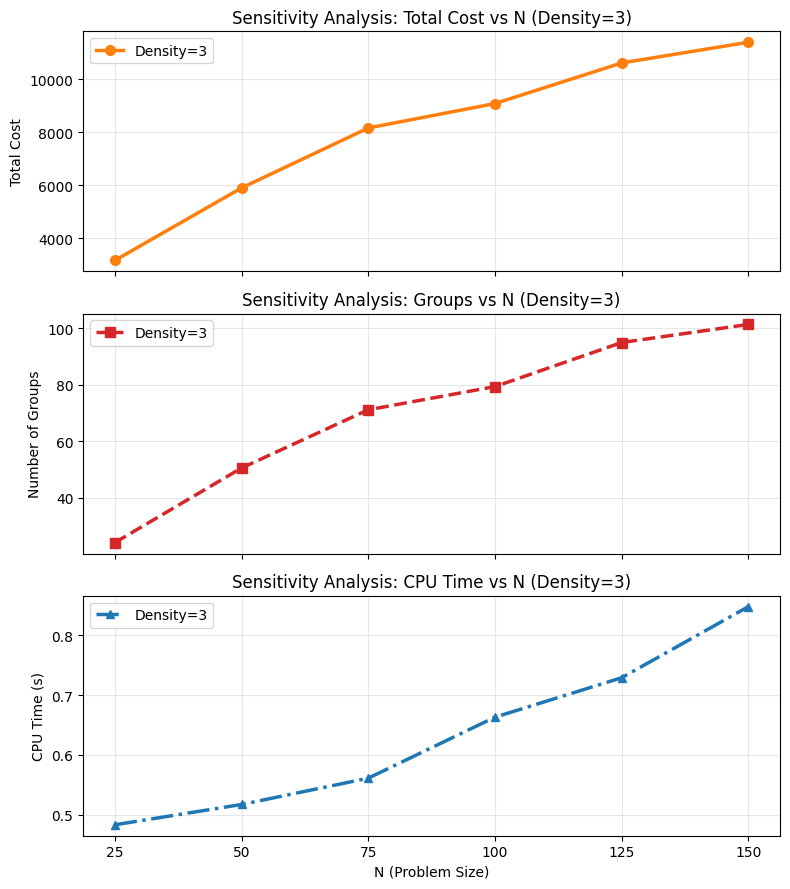

   ✅ Saved: N_sensitivity_COST_results_2026/sensitivity_density_3_vs_N.png

📊 Processing density 10...
   Data shape: (6, 3)


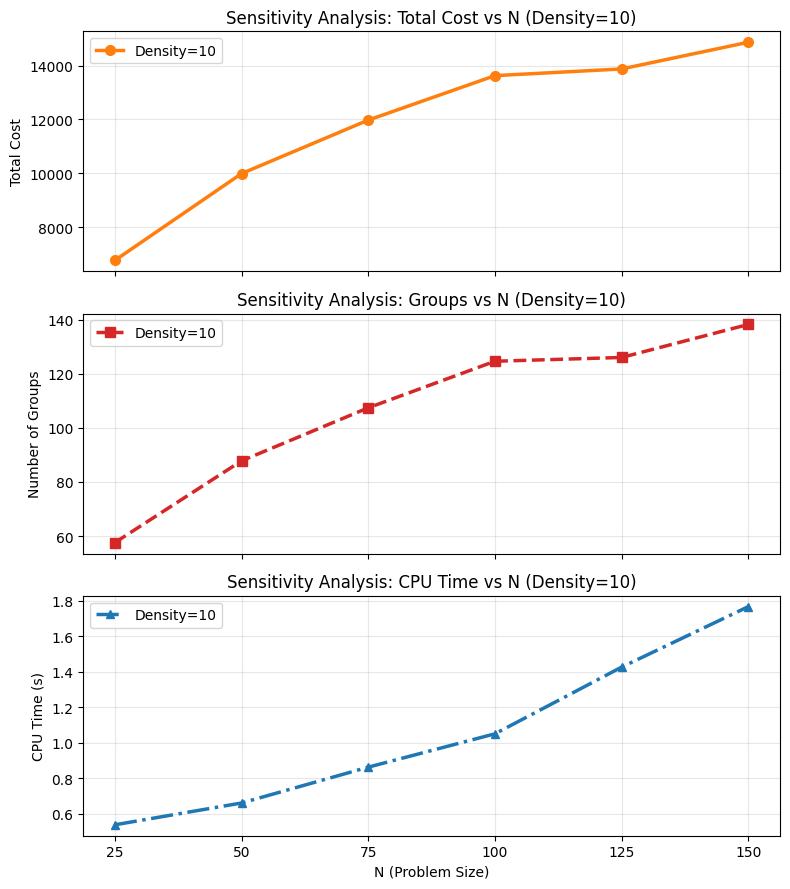

   ✅ Saved: N_sensitivity_COST_results_2026/sensitivity_density_10_vs_N.png

📊 Processing density 20...
   Data shape: (6, 3)


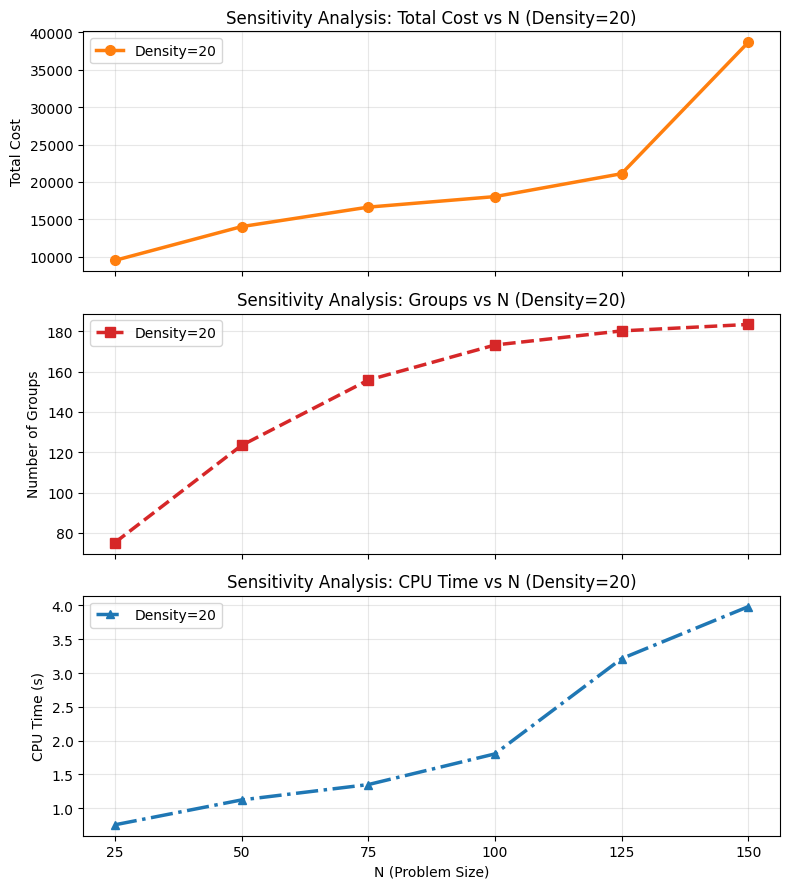

   ✅ Saved: N_sensitivity_COST_results_2026/sensitivity_density_20_vs_N.png

🎉 All density sensitivity plots completed!


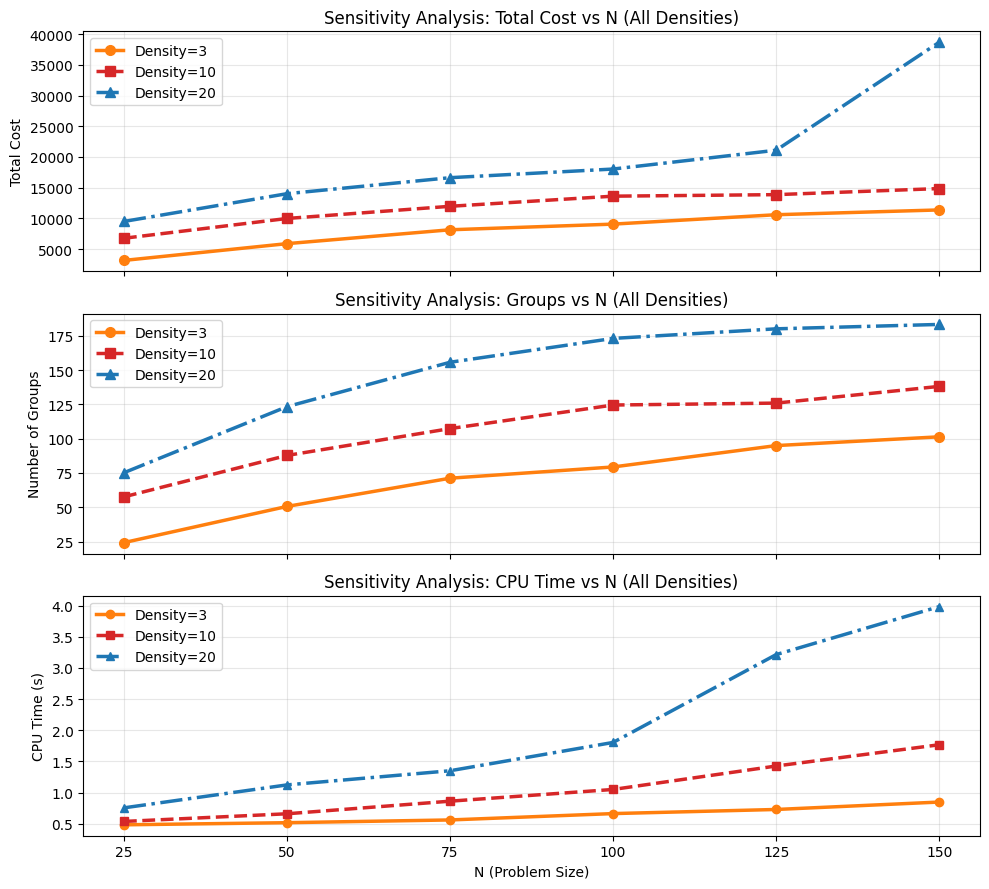

✅ Comparison plot saved: N_sensitivity_COST_results_2026/sensitivity_all_densities_vs_N.png

🎯 All plots generated successfully!

📊 Output files:
   ✅ sensitivity_all_densities_vs_N.png
   ✅ sensitivity_density_10_vs_N.png
   ✅ sensitivity_density_3_vs_N.png
   ✅ sensitivity_density_20_vs_N.png


In [ ]:
# visulization
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import glob
import os

# 🔥 🔥 🔥 设置纯英文，无中文
plt.rcParams["font.family"] = "DejaVu Sans"

def plot_N_sensitivity_per_density(results_dir='N_sensitivity_COST_results_2026'):
    """
    为每个任务密度分别画N敏感性分析图
    完全修复维度错误 + 纯英文
    """
    
    # 🔥 任务密度列表
    task_densities = [3, 10, 20]
    
    # 🔥 从实际数据获取N值（动态适配）
    summary_files = glob.glob(f"{results_dir}/SUMMARY_density_*_all_N.csv")
    if not summary_files:
        print(f"❌ No summary files found in {results_dir}")
        return
    
    # 🔥 读取第一个文件获取实际N值
    sample_df = pd.read_csv(summary_files[0])
    N_values = sorted(sample_df['N'].unique())
    print(f"🔍 Detected N values: {N_values}")
    
    for density in task_densities:
        print(f"\n📊 Processing density {density}...")
        
        # 🔥 读取该密度的汇总数据
        summary_file = f"{results_dir}/SUMMARY_density_{density}_all_N.csv"
        if not os.path.exists(summary_file):
            print(f"⚠️  File not found: {summary_file}")
            continue
            
        df = pd.read_csv(summary_file)
        
        # 🔥 计算每个N的平均值（多seeds取平均）
        agg_data = df.groupby('N').agg({
            'Total_cost': 'mean',
            'nb_groups': 'mean',
            'total_clustering_cpu_s': 'mean'
        }).round(3).reindex(N_values)  # 🔥 确保N顺序正确
        
        # 🔥 检查数据完整性
        if len(agg_data) != len(N_values):
            print(f"⚠️  Warning: Density {density} has {len(agg_data)} N points, expected {len(N_values)}")
            N_values_plot = agg_data.index.tolist()
        else:
            N_values_plot = N_values
            
        print(f"   Data shape: {agg_data.shape}")
        
        # 🔥 🔥 🔥 三个子图
        fig, axes = plt.subplots(3, 1, figsize=(8, 9), sharex=True)
        
        # ========== Plot 1: Total Cost ==========
        axes[0].plot(N_values_plot, agg_data['Total_cost'].values, 
                    "o-", color="#ff7f0e", linewidth=2.5, markersize=7, 
                    label=f"Density={density}")
        axes[0].set_ylabel("Total Cost")
        axes[0].set_title(f"Sensitivity Analysis: Total Cost vs N (Density={density})")
        axes[0].legend(loc="upper left")
        axes[0].grid(True, alpha=0.3)
        
        # ========== Plot 2: Number of Groups ==========
        axes[1].plot(N_values_plot, agg_data['nb_groups'].values, 
                    "s--", color="#d62728", linewidth=2.5, markersize=7, 
                    label=f"Density={density}")
        axes[1].set_ylabel("Number of Groups")
        axes[1].set_title(f"Sensitivity Analysis: Groups vs N (Density={density})")
        axes[1].legend(loc="upper left")
        axes[1].grid(True, alpha=0.3)
        
        # ========== Plot 3: CPU Time ==========
        axes[2].plot(N_values_plot, agg_data['total_clustering_cpu_s'].values, 
                    "^-.", color="#1f77b4", linewidth=2.5, markersize=6, 
                    label=f"Density={density}")
        axes[2].set_xlabel("N (Problem Size)")
        axes[2].set_ylabel("CPU Time (s)")
        axes[2].set_title(f"Sensitivity Analysis: CPU Time vs N (Density={density})")
        axes[2].legend(loc="upper left")
        axes[2].grid(True, alpha=0.3)
        
        # 🔥 X轴设置
        axes[2].set_xticks(N_values_plot)
        
        plt.tight_layout()
        
        # 🔥 保存高清图片
        output_file = f"{results_dir}/sensitivity_density_{density}_vs_N.png"
        plt.savefig(output_file, dpi=300, bbox_inches='tight')
        plt.show()
        print(f"   ✅ Saved: {output_file}")
    
    print("\n🎉 All density sensitivity plots completed!")

# 🔥 🔥 🔥 所有密度对比图（修复版）
def plot_all_densities_comparison(results_dir='N_sensitivity_COST_results_2026'):
    """All densities comparison - fixed version"""
    
    task_densities = [3, 10, 20]
    summary_files = glob.glob(f"{results_dir}/SUMMARY_density_*_all_N.csv")
    
    if not summary_files:
        print(f"❌ No summary files found!")
        return
    
    # 🔥 获取所有N值
    sample_df = pd.read_csv(summary_files[0])
    N_values = sorted(sample_df['N'].unique())
    
    fig, axes = plt.subplots(3, 1, figsize=(10, 9), sharex=True)
    
    colors = ['#ff7f0e', '#d62728', '#1f77b4']
    markers = ['o', 's', '^']
    linestyles = ['-', '--', '-.']
    
    for i, density in enumerate(task_densities):
        summary_file = f"{results_dir}/SUMMARY_density_{density}_all_N.csv"
        if not os.path.exists(summary_file):
            print(f"⚠️  Skipping density {density}")
            continue
            
        df = pd.read_csv(summary_file)
        agg_data = df.groupby('N').agg({
            'Total_cost': 'mean',
            'nb_groups': 'mean',
            'total_clustering_cpu_s': 'mean'
        }).round(3).reindex(N_values)
        
        N_plot = agg_data.index.dropna().tolist()
        
        # Plot 1: Total Cost
        axes[0].plot(N_plot, agg_data.loc[N_plot, 'Total_cost'].values, 
                    marker=markers[i], linestyle=linestyles[i], 
                    color=colors[i], linewidth=2.5, markersize=7,
                    label=f"Density={density}")
        
        # Plot 2: Groups
        axes[1].plot(N_plot, agg_data.loc[N_plot, 'nb_groups'].values, 
                    marker=markers[i], linestyle=linestyles[i], 
                    color=colors[i], linewidth=2.5, markersize=7,
                    label=f"Density={density}")
        
        # Plot 3: CPU Time
        axes[2].plot(N_plot, agg_data.loc[N_plot, 'total_clustering_cpu_s'].values, 
                    marker=markers[i], linestyle=linestyles[i], 
                    color=colors[i], linewidth=2.5, markersize=6,
                    label=f"Density={density}")
    
    # 🔥 图表设置（纯英文）
    axes[0].set_ylabel("Total Cost")
    axes[0].set_title("Sensitivity Analysis: Total Cost vs N (All Densities)")
    axes[0].legend(loc="upper left")
    axes[0].grid(True, alpha=0.3)
    
    axes[1].set_ylabel("Number of Groups")
    axes[1].set_title("Sensitivity Analysis: Groups vs N (All Densities)")
    axes[1].legend(loc="upper left")
    axes[1].grid(True, alpha=0.3)
    
    axes[2].set_xlabel("N (Problem Size)")
    axes[2].set_ylabel("CPU Time (s)")
    axes[2].set_title("Sensitivity Analysis: CPU Time vs N (All Densities)")
    axes[2].legend(loc="upper left")
    axes[2].grid(True, alpha=0.3)
    axes[2].set_xticks(N_values)
    
    plt.tight_layout()
    output_file = f"{results_dir}/sensitivity_all_densities_vs_N.png"
    plt.savefig(output_file, dpi=300, bbox_inches='tight')
    plt.show()
    print(f"✅ Comparison plot saved: {output_file}")

# 🔥 🔥 🔥 主运行（修复版）
if __name__ == "__main__":
    # 🔥 修改为你的实际目录名
    results_dir = 'N_sensitivity_COST_results_2026'  
    
    print(f"📁 Using results directory: {results_dir}")
    print("🔍 Available files:")
    for f in glob.glob(f"{results_dir}/*.csv"):
        print(f"   {os.path.basename(f)}")
    
    # 1️⃣ 每个密度单独画图
    plot_N_sensitivity_per_density(results_dir)
    
    # 2️⃣ 所有密度对比图
    plot_all_densities_comparison(results_dir)
    
    print("\n🎯 All plots generated successfully!")
    print("\n📊 Output files:")
    for f in glob.glob(f"{results_dir}/sensitivity_*.png"):
        print(f"   ✅ {os.path.basename(f)}")
